# Drug Galaxy — Analysis

**Question:** Do drugs that treat the same conditions look alike chemically?

This notebook reads the cleaned data from `pipeline/clean.py` and works through the analysis step by step.

## Setup

In [6]:
import pandas as pd
from rdkit import Chem, DataStructs
from rdkit.Chem import Draw, rdFingerprintGenerator

## 1. Load the cleaned data and apply the size filter

Molecules with fewer than 6 heavy atoms (acetic acid, citric acid, bicarbonate...) are simple chemicals rather than drugs in the sense of the question, and their fingerprints are almost empty, so they're dropped here.

In [7]:
# keep_default_na=False so blank atc cells stay as "" instead of NaN
drugs = pd.read_csv("../data/processed/drugs_clean.csv", keep_default_na=False)
print("clean drugs:", len(drugs))

MIN_HEAVY_ATOMS = 6
too_small = drugs["heavy_atoms"] < MIN_HEAVY_ATOMS
print("dropped as too small:", too_small.sum())
print(drugs[too_small]["name"].head(18).tolist())

drugs = drugs[~too_small].reset_index(drop=True)
print("drugs left:", len(drugs))

clean drugs: 2154
dropped as too small: 18
['POTASSIUM BICARBONATE', 'VINYL CHLORIDE', 'GLYCINE', 'CHLOROFORM', 'ETHYL CHLORIDE', 'DIMETHYL SULFOXIDE', 'ISOPROPYL ALCOHOL', 'ALCOHOL', 'ACETIC ACID', 'ACETOHYDROXAMIC ACID', 'CYSTEAMINE', 'TRICHLOROETHANE', 'PROPIOLACTONE', 'HYDROXYUREA', 'UREA C 14', 'UREA C 13', 'UREA', 'GUANIDINE']
drugs left: 2136


## 2. Compute fingerprints

Each molecule becomes a **Morgan fingerprint**: 2,048 slots of 0/1. RDKit looks at every atom plus its neighborhood out to 2 bonds (`radius=2`), and each neighborhood pattern switches on a slot.

In [8]:
# one generator, reused for every molecule
fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

mols = [Chem.MolFromSmiles(s) for s in drugs["smiles"]]
fps = [fp_gen.GetFingerprint(m) for m in mols]

print("fingerprints:", len(fps))

fingerprints: 2136


### Look at one fingerprint

How many of the 2,048 slots does a real drug switch on?

IBUPROFEN CC(C)Cc1ccc(C(C)C(=O)O)cc1
slots switched on: 25 out of 2048
which slots: [1, 79, 80, 283, 310, 389, 650, 807, 854, 857, 900, 921, 955, 1057, 1146, 1257, 1365, 1380, 1750, 1754, 1844, 1847, 1853, 1873, 1917]


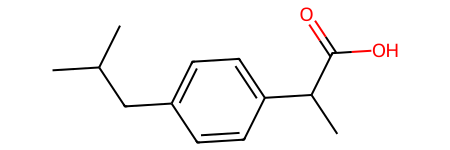

In [9]:
i = drugs.index[drugs["name"] == "IBUPROFEN"][0]

print(drugs.loc[i, "name"], drugs.loc[i, "smiles"])
print("slots switched on:", fps[i].GetNumOnBits(), "out of", fps[i].GetNumBits())
print("which slots:", list(fps[i].GetOnBits()))

mols[i]

## 3. Sanity check: does similarity make sense?

**Tanimoto similarity** = slots both drugs have on ÷ slots either drug has on (0 = nothing shared, 1 = identical).

If fingerprints work, ibuprofen's closest matches should be other painkillers like it, and an unrelated drug should score low.

In [10]:
# similarity of ibuprofen to every drug at once
sims = DataStructs.BulkTanimotoSimilarity(fps[i], fps)
drugs["sim_to_ibuprofen"] = sims

# drop ibuprofen itself (it would match itself with 1.0), then take the top 5
closest = drugs.drop(i).sort_values("sim_to_ibuprofen", ascending=False).head(5)
closest[["name", "atc_groups", "sim_to_ibuprofen"]]

,name,atc_groups,sim_to_ibuprofen
537,DEXIBUPROFEN,M,1.000000
239,IBUFENAC,,0.600000
2008,LOXOPROFEN,M,0.487805
970,SUPROFEN,M,0.461538
204,NAPROXEN,G;M,0.421053


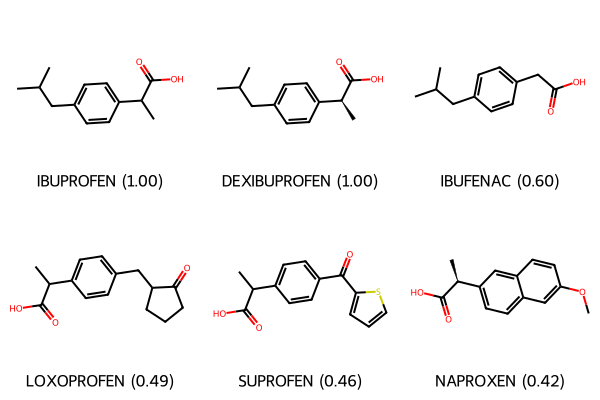

In [11]:
# draw ibuprofen and its 5 closest matches
show = [i] + list(closest.index)
Draw.MolsToGridImage(
    [mols[j] for j in show],
    legends=[f"{drugs.loc[j, 'name']} ({drugs.loc[j, 'sim_to_ibuprofen']:.2f})" for j in show],
    molsPerRow=3,
)

In [13]:
# compare with something unrelated
j = drugs.index[drugs["name"] == "PENICILLIN G"][0]
print("ibuprofen vs penicillin G:", round(DataStructs.TanimotoSimilarity(fps[i], fps[j]), 2))

# and how similar are two random drugs, on average?
print("average similarity to ibuprofen:", round(drugs["sim_to_ibuprofen"].mean(), 2))

ibuprofen vs penicillin G: 0.17
average similarity to ibuprofen: 0.12


## Notes

**Sanity check: ibuprofen's closest matches**

- Dexibuprofen matched at 1.00. It's identical to ibuprofen except the wedge
  points a different way (mirror image, like left and right hands). Regular
  ibuprofen is a 50/50 mix of both forms, so they're basically the same drug.
  - The fingerprint can't tell mirror images apart, so it scores them as
    identical → limitation to mention in the report.
- The other 4 close matches (ibufenac 0.60, loxoprofen 0.49, suprofen 0.46,
  naproxen 0.42) are all anti-inflammatory painkillers. They share the same
  key piece (an acid "hook" off a ring) and differ on the other end.
  - The more of the structure they share, the higher the score.
- Every classified match was in group M (musculo-skeletal), same as ibuprofen.
- Ibufenac has no class in ChEMBL but sits right with the painkillers, and it
  is one → unclassified drugs can still be placed by their neighbors.
- Unrelated drug (penicillin G) only scored 0.17, and the average drug scored
  0.12, so 0.4-0.6 is way above normal.

**Takeaway:** the fingerprints work. Similar structure = high score, and the
look-alikes treat the same thing. Next: test this on all 2,136 drugs.